In [1]:
import os

import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

os.makedirs("../submission", exist_ok=True)

digits = load_digits()
X, y = digits.data, digits.target
X.shape

(1797, 64)

In [2]:
def plot_embedding(embedding, title, filename):
    plt.figure(figsize=(8, 7))
    scatter = plt.scatter(
        embedding[:, 0], embedding[:, 1], c=y, cmap="tab10", s=8, alpha=0.8
    )
    plt.legend(*scatter.legend_elements(), title="Dígito", loc="best", fontsize=8)
    plt.title(title)
    plt.xticks([])
    plt.yticks([])
    plt.savefig(f"../submission/{filename}", dpi=120, bbox_inches="tight")
    plt.show()

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print("Varianza explicada:", pca.explained_variance_ratio_.sum().round(3))
plot_embedding(X_pca, "Digits - PCA", "digits_pca.png")

Varianza explicada: 0.285


<Figure size 800x700 with 1 Axes>

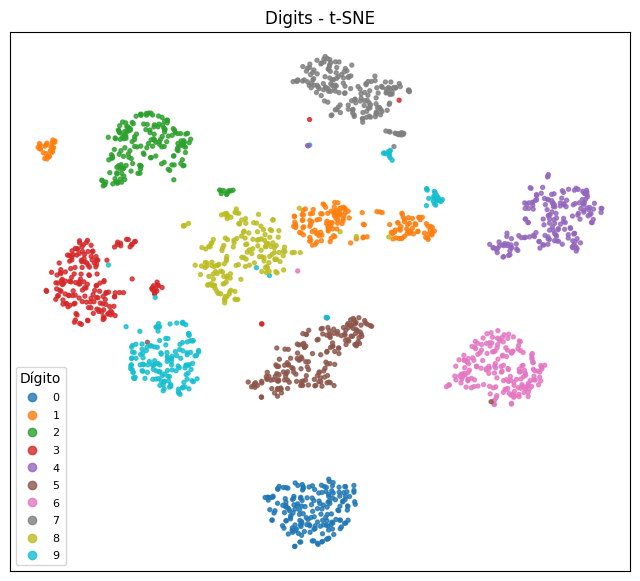

In [4]:
from sklearn.manifold import TSNE

X_tsne = TSNE(n_components=2, random_state=42, init="pca").fit_transform(X)
plot_embedding(X_tsne, "Digits - t-SNE", "digits_tsne.png")

/Users/druiz35/Documents/uni_stuff/predictiva/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/druiz35/Documents/uni_stuff/predictiva/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


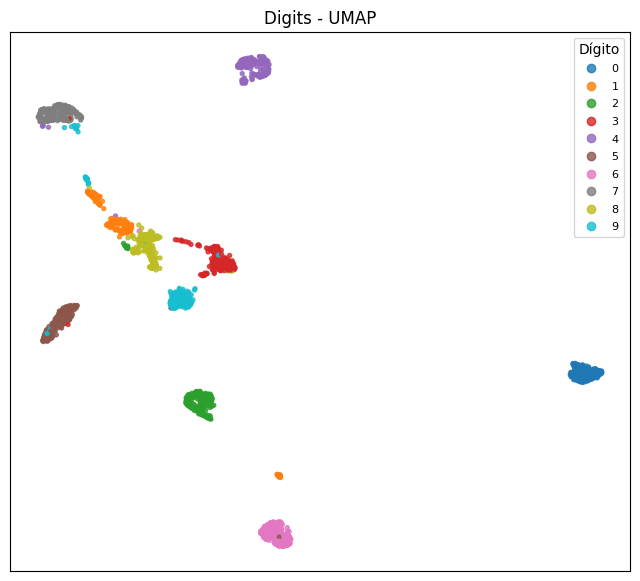

In [5]:
import umap

X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X)
plot_embedding(X_umap, "Digits - UMAP", "digits_umap.png")